# FCN-8s — FINAL 20-PATIENT LOCKED-TEST ENSEMBLE

This notebook performs the **final untouched 20-patient locked-test evaluation** for the reimplemented FCN-8s baseline.

## Frozen protocol — do not modify after seeing test results

Primary inference rule:

1. load the five frozen Fold 0–4 `best_model.pt` checkpoints;
2. run all five models on each locked-test patient;
3. average their 4-class softmax probabilities with equal weight;
4. use `argmax` of the averaged probability map;
5. **no threshold tuning**;
6. **no calibration fitting on the test set**;
7. **no extra post-processing or test-set optimization**.

The inference rule was fixed before this baseline's locked-test evaluation.

## Kaggle inputs

Attach only:

1. the original **MS3SEG** dataset;
2. the completed FCN-8s Fold 0 TRANSFER output;
3. Fold 1 TRANSFER output;
4. Fold 2 TRANSFER output;
5. Fold 3 TRANSFER output;
6. Fold 4 TRANSFER output.

Do not attach or use ablation checkpoints for this test.


In [1]:
from __future__ import annotations

import os
import re
import gc
import io
import json
import math
import random
import warnings
import hashlib
import zipfile
import shutil
from functools import lru_cache
from pathlib import Path
from typing import Literal

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy import ndimage
from scipy.optimize import linear_sum_assignment

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INFERENCE_BATCH_SIZE = 4
LOCKED_TEST_EVALUATION = True
EXPECTED_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

OUTPUT_DIR = Path("/kaggle/working/fcn8s_final_locked_test")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
if DEVICE.type != "cuda":
    warnings.warn("A GPU is strongly recommended. Select a T4 GPU in Kaggle Settings.")

print("FINAL LOCKED-TEST MODE: ENABLED")


Device: cuda
FINAL LOCKED-TEST MODE: ENABLED


In [2]:
def discover_ms3seg_root():
    required = {"MS_100_patient_preprocessed", "MS_100_patient_masks"}

    preferred = [
        Path("/kaggle/input/ms3seg/MS3SEG"),
        Path("/kaggle/input/ms3seg"),
        Path("/kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG"),
    ]

    for candidate in preferred:
        if not candidate.exists() or not candidate.is_dir():
            continue
        names = {p.name for p in candidate.iterdir() if p.is_dir()}
        if required.issubset(names):
            return candidate

    input_root = Path("/kaggle/input")
    for preprocessed in input_root.rglob("MS_100_patient_preprocessed"):
        candidate = preprocessed.parent
        if (candidate / "MS_100_patient_masks").exists():
            return candidate

    raise FileNotFoundError(
        "MS3SEG was not found. Attach the original MS3SEG Kaggle dataset."
    )


TRANSFER_PREFIX = "MS3SEG_BASELINE_FCN8S_FOLD"
EXPECTED_METADATA_MODEL = "Reimplemented-FCN-8s-common-protocol"


def discover_all_fold_bundles():
    input_root = Path("/kaggle/input")
    extraction_root = Path(
        "/kaggle/working/fcn8s_final_test_checkpoint_extract"
    )
    extraction_root.mkdir(parents=True, exist_ok=True)

    bundles = {}

    for fold in range(5):
        # First support literal transfer ZIP inputs.
        zip_candidates = [
            p for p in input_root.rglob("*.zip")
            if p.is_file()
            and p.name.startswith(
                f"{TRANSFER_PREFIX}{fold}_FULL60_TRANSFER"
            )
        ]

        if zip_candidates:
            zip_path = sorted(
                zip_candidates,
                key=lambda p: p.stat().st_size,
                reverse=True,
            )[0]

            fold_dir = extraction_root / f"fold{fold}"
            if fold_dir.exists():
                shutil.rmtree(fold_dir)
            fold_dir.mkdir(parents=True, exist_ok=True)

            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(fold_dir)

            checkpoint_hits = list(fold_dir.rglob("best_model.pt"))
            split_hits = list(
                fold_dir.rglob("patient_level_5fold_split.csv")
            )
            metadata_hits = list(
                fold_dir.rglob("transfer_metadata.json")
            )

            if len(checkpoint_hits) != 1 or len(split_hits) != 1:
                raise FileNotFoundError(
                    f"Fold {fold} transfer ZIP must contain exactly one "
                    "best_model.pt and patient_level_5fold_split.csv: "
                    f"{zip_path}"
                )

            checkpoint = checkpoint_hits[0]
            split_path = split_hits[0]
            metadata_path = (
                metadata_hits[0]
                if len(metadata_hits) == 1
                else None
            )

            if metadata_path is not None:
                metadata = json.loads(
                    metadata_path.read_text(encoding="utf-8")
                )
                if int(metadata.get("fold", fold)) != fold:
                    raise RuntimeError(
                        f"Transfer metadata fold mismatch for Fold {fold}."
                    )
                model_name = str(metadata.get("model", ""))
                if model_name and model_name != EXPECTED_METADATA_MODEL:
                    raise RuntimeError(
                        f"Wrong model attached for Fold {fold}: {model_name}"
                    )

            bundles[fold] = {
                "checkpoint": checkpoint,
                "split": split_path,
                "metadata": metadata_path,
                "source": zip_path,
            }
            continue

        # Also support Kaggle datasets where the transfer ZIP was unpacked.
        direct_candidates = []

        for meta_path in input_root.rglob("transfer_metadata.json"):
            try:
                metadata = json.loads(
                    meta_path.read_text(encoding="utf-8")
                )
            except Exception:
                continue

            try:
                meta_fold = int(metadata.get("fold", -1))
            except Exception:
                continue

            if meta_fold != fold:
                continue

            if str(metadata.get("model", "")) != EXPECTED_METADATA_MODEL:
                continue

            checkpoint = meta_path.parent / "best_model.pt"
            split_path = (
                meta_path.parent / "patient_level_5fold_split.csv"
            )

            if checkpoint.exists() and split_path.exists():
                direct_candidates.append(
                    (checkpoint, split_path, meta_path)
                )

        if len(direct_candidates) != 1:
            raise FileNotFoundError(
                f"Could not uniquely find FCN-8s Fold {fold}. "
                f"Attach all five FCN-8s Fold 0–4 TRANSFER outputs."
            )

        checkpoint, split_path, metadata_path = direct_candidates[0]
        bundles[fold] = {
            "checkpoint": checkpoint,
            "split": split_path,
            "metadata": metadata_path,
            "source": checkpoint.parent,
        }

    return bundles


DATA_ROOT = discover_ms3seg_root()
CHECKPOINT_BUNDLES = discover_all_fold_bundles()

PREPROCESSED_DIR = DATA_ROOT / "MS_100_patient_preprocessed"
MASKS_DIR = DATA_ROOT / "MS_100_patient_masks"

print("Dataset root:", DATA_ROOT)
for fold, info in CHECKPOINT_BUNDLES.items():
    print(f"Fold {fold} checkpoint source:", info["source"])


Dataset root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG
Fold 0 checkpoint source: /kaggle/input/datasets/sabatasnim123/fcn-fold04-transfer-outputs/MS3SEG_BASELINE_FCN8S_FOLD0_FULL60_TRANSFER
Fold 1 checkpoint source: /kaggle/input/datasets/sabatasnim123/fcn-fold04-transfer-outputs/MS3SEG_BASELINE_FCN8S_FOLD1_FULL60_TRANSFER
Fold 2 checkpoint source: /kaggle/input/datasets/sabatasnim123/fcn-fold04-transfer-outputs/MS3SEG_BASELINE_FCN8S_FOLD2_FULL60_TRANSFER
Fold 3 checkpoint source: /kaggle/input/datasets/sabatasnim123/fcn-fold04-transfer-outputs/MS3SEG_BASELINE_FCN8S_FOLD3_FULL60_TRANSFER
Fold 4 checkpoint source: /kaggle/input/datasets/sabatasnim123/fcn-fold04-transfer-outputs/MS3SEG_BASELINE_FCN8S_FOLD4_FULL60_TRANSFER


In [3]:
mask_roots = [
    path
    for path in MASKS_DIR.iterdir()
    if path.is_dir()
]


def select_mask_root(kind):
    if kind == "vent":
        matches = [
            path
            for path in mask_roots
            if "vent" in path.name.lower()
        ]

    elif kind == "nwmh":
        matches = [
            path
            for path in mask_roots
            if (
                "nwmh" in path.name.lower()
                or "normal" in path.name.lower()
            )
            and "abwmh" not in path.name.lower()
            and "abnormal" not in path.name.lower()
        ]

    else:
        matches = [
            path
            for path in mask_roots
            if (
                "abwmh" in path.name.lower()
                or "abnormal" in path.name.lower()
            )
        ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {kind} mask root, found: {matches}"
        )

    return matches[0]


VENT_ROOT = select_mask_root("vent")
NWMH_ROOT = select_mask_root("nwmh")
ABWMH_ROOT = select_mask_root("abwmh")


def find_unique_file(
    folder,
    patterns,
    description,
):
    found = []

    for pattern in patterns:
        found.extend(
            folder.glob(pattern)
        )

    unique = []
    seen = set()

    for path in found:
        if (
            path.is_file()
            and path not in seen
        ):
            unique.append(path)
            seen.add(path)

    if len(unique) != 1:
        raise FileNotFoundError(
            f"{description}: expected one file in {folder}; "
            f"found {len(unique)}: {unique}"
        )

    return unique[0]


patient_dirs = sorted(
    path
    for path in PREPROCESSED_DIR.iterdir()
    if (
        path.is_dir()
        and re.fullmatch(
            r"\d{3}",
            path.name,
        )
    )
)

records = []

for patient_dir in patient_dirs:
    patient_id = patient_dir.name

    records.append({
        "patient_id": patient_id,
        "flair": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_FLAIR.nii",
                    f"{patient_id}_FLAIR.nii.gz",
                ],
                f"{patient_id} FLAIR",
            )
        ),
        "t1": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T1WI_reg.nii",
                    f"{patient_id}_T1WI_reg.nii.gz",
                    "*T1*reg*.nii*",
                ],
                f"{patient_id} T1",
            )
        ),
        "t2": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T2WI_reg.nii",
                    f"{patient_id}_T2WI_reg.nii.gz",
                    "*T2*reg*.nii*",
                ],
                f"{patient_id} T2",
            )
        ),
        "vent": str(
            find_unique_file(
                VENT_ROOT / patient_id,
                [
                    f"{patient_id}_Vent_Mask.nii",
                    f"{patient_id}_Vent_Mask.nii.gz",
                    "*Vent*Mask*.nii*",
                ],
                f"{patient_id} ventricle mask",
            )
        ),
        "nwmh": str(
            find_unique_file(
                NWMH_ROOT / patient_id,
                [
                    f"{patient_id}_nWMH_Mask.nii",
                    f"{patient_id}_nWMH_Mask.nii.gz",
                    "*nWMH*Mask*.nii*",
                ],
                f"{patient_id} normal-WMH mask",
            )
        ),
        "abwmh": str(
            find_unique_file(
                ABWMH_ROOT / patient_id,
                [
                    f"{patient_id}_abWMH_Mask.nii",
                    f"{patient_id}_abWMH_Mask.nii.gz",
                    "*abWMH*Mask*.nii*",
                ],
                f"{patient_id} abnormal-WMH mask",
            )
        ),
    })


manifest = (
    pd.DataFrame(records)
    .sort_values("patient_id")
    .reset_index(drop=True)
)

manifest["patient_id"] = (
    manifest["patient_id"]
    .astype(str)
    .str.zfill(3)
)

manifest_by_id = manifest.set_index("patient_id")

print("Patients found:", len(manifest))

if len(manifest) != 100:
    warnings.warn(
        f"Expected 100 patients but found {len(manifest)}."
    )

display(manifest.head())

Patients found: 100


,patient_id,flair,t1,t2,vent,nwmh,abwmh
0,001,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
1,002,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
2,003,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
3,004,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
4,005,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...


In [4]:
# Verify the frozen split carried by every checkpoint package.
split_hashes = {}
split_frames = {}

for fold, info in CHECKPOINT_BUNDLES.items():
    raw = info["split"].read_bytes()
    sha = hashlib.sha256(raw).hexdigest()
    split_hashes[fold] = sha

    frame = pd.read_csv(
        info["split"],
        dtype={"patient_id": str},
    )
    frame["patient_id"] = (
        frame["patient_id"]
        .astype(str)
        .str.zfill(3)
    )
    split_frames[fold] = frame

print("Split hashes:", split_hashes)

if len(set(split_hashes.values())) != 1:
    raise RuntimeError(
        "The five checkpoint packages do not carry identical frozen splits."
    )

if next(iter(split_hashes.values())) != EXPECTED_SPLIT_SHA256:
    raise RuntimeError(
        "Frozen split checksum differs from the completed Fold-0 experiment."
    )

split_df = split_frames[0].copy()

locked_test_ids = sorted(
    split_df.loc[
        split_df["role"] == "test",
        "patient_id",
    ]
    .astype(str)
    .str.zfill(3)
    .unique()
)

if len(locked_test_ids) != 20:
    raise RuntimeError(
        f"Expected exactly 20 locked-test patients, found {len(locked_test_ids)}."
    )

development_ids = sorted(
    split_df.loc[
        split_df["role"].isin(["train", "val"]),
        "patient_id",
    ]
    .astype(str)
    .str.zfill(3)
    .unique()
)

if len(development_ids) != 80:
    raise RuntimeError(
        f"Expected 80 development patients, found {len(development_ids)}."
    )

if set(locked_test_ids) & set(development_ids):
    raise RuntimeError(
        "Development / locked-test overlap detected."
    )

dataset_ids = set(manifest["patient_id"])
split_ids = set(
    split_df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

if dataset_ids != split_ids:
    raise RuntimeError(
        "MS3SEG patient IDs do not match the frozen five-fold split."
    )

print("Frozen split verification: PASSED")
print("Development patients:", len(development_ids))
print("Locked-test patients to evaluate:", len(locked_test_ids))
print("Locked-test IDs are fixed by the original split; no patient selection is performed.")


Split hashes: {0: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 1: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 2: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 3: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459', 4: 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459'}
Frozen split verification: PASSED
Development patients: 80
Locked-test patients to evaluate: 20
Locked-test IDs are fixed by the original split; no patient selection is performed.


In [5]:
@lru_cache(maxsize=48)
def load_volume(path):
    return np.asarray(
        nib.load(
            path,
            mmap=True,
        ).dataobj,
        dtype=np.float32,
    )


@lru_cache(maxsize=36)
def load_normalized_volume(path):
    array = load_volume(path).copy()

    finite = np.isfinite(array)
    nonzero = (
        finite
        & (
            np.abs(array)
            > 1e-6
        )
    )

    if nonzero.sum() < 100:
        return np.nan_to_num(
            array
        ).astype(np.float32)

    low, high = np.percentile(
        array[nonzero],
        [
            0.5,
            99.5,
        ],
    )

    high = max(
        high,
        low + 1.0,
    )

    array = np.clip(
        array,
        low,
        high,
    )

    array = (
        array
        - array[nonzero].mean()
    ) / (
        array[nonzero].std()
        + 1e-6
    )

    array[~finite] = 0.0

    return array.astype(
        np.float32
    )


@lru_cache(maxsize=48)
def load_binary_mask(path):
    return (
        load_volume(path)
        > 0
    ).astype(np.uint8)


def compose_target(row):
    ventricle = load_binary_mask(
        row.vent
    )

    normal_wmh = load_binary_mask(
        row.nwmh
    )

    abnormal_wmh = load_binary_mask(
        row.abwmh
    )

    target = np.zeros(
        ventricle.shape,
        dtype=np.uint8,
    )

    target[
        ventricle
        > 0
    ] = 1

    target[
        normal_wmh
        > 0
    ] = 2

    target[
        abnormal_wmh
        > 0
    ] = 3

    return target


def triplet(
    volume,
    slice_index,
):
    depth = volume.shape[2]

    indices = [
        max(
            0,
            slice_index - 1,
        ),
        slice_index,
        min(
            depth - 1,
            slice_index + 1,
        ),
    ]

    return np.stack(
        [
            volume[
                :,
                :,
                index,
            ]
            for index in indices
        ],
        axis=0,
    )


def build_patient_inputs(row):
    flair = load_normalized_volume(
        row.flair
    )

    t1 = load_normalized_volume(
        row.t1
    )

    t2 = load_normalized_volume(
        row.t2
    )

    depth = flair.shape[2]

    inputs = []

    for slice_index in range(depth):
        inputs.append(
            np.concatenate(
                [
                    triplet(
                        flair,
                        slice_index,
                    ),
                    triplet(
                        t1,
                        slice_index,
                    ),
                    triplet(
                        t2,
                        slice_index,
                    ),
                ],
                axis=0,
            )
        )

    return np.stack(
        inputs,
        axis=0,
    ).astype(np.float32)

In [6]:

class BaselineConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, repeats=2):
        super().__init__()
        layers = []
        current = in_ch

        for _ in range(repeats):
            groups = 8
            while out_ch % groups != 0 and groups > 1:
                groups //= 2

            layers.extend([
                nn.Conv2d(
                    current,
                    out_ch,
                    kernel_size=3,
                    padding=1,
                    bias=False,
                ),
                nn.GroupNorm(groups, out_ch),
                nn.SiLU(inplace=True),
            ])
            current = out_ch

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class BaselineOutputMixin:
    @staticmethod
    def pack(logits):
        return {
            "segmentation_logits": logits,
            "aux_logits_d2": None,
            "aux_logits_d1": None,
        }

class FCN8sBaseline(nn.Module):
    """
    FCN-8s-style 2.5D multimodal baseline.

    The encoder is VGG-like. Coarse class scores are fused with
    1/16- and 1/8-resolution skip-score maps before final upsampling.
    No pretrained weights are used because the input has 9 channels.
    """

    def __init__(self, base=24, num_classes=4, **kwargs):
        super().__init__()

        b = int(base)
        c1, c2, c3, c4, c5 = (
            b,
            b * 2,
            b * 4,
            b * 8,
            b * 12,
        )

        self.block1 = BaselineConvBlock(9, c1, repeats=2)
        self.block2 = BaselineConvBlock(c1, c2, repeats=2)
        self.block3 = BaselineConvBlock(c2, c3, repeats=3)
        self.block4 = BaselineConvBlock(c3, c4, repeats=3)
        self.block5 = BaselineConvBlock(c4, c5, repeats=3)

        self.pool = nn.MaxPool2d(2, 2)

        self.context = nn.Sequential(
            BaselineConvBlock(c5, c5, repeats=2),
            nn.Dropout2d(p=0.20),
        )

        self.score32 = nn.Conv2d(c5, num_classes, 1)
        self.score16 = nn.Conv2d(c4, num_classes, 1)
        self.score8 = nn.Conv2d(c3, num_classes, 1)

    def forward(self, x):
        input_size = x.shape[-2:]

        x1 = self.block1(x)
        p1 = self.pool(x1)

        x2 = self.block2(p1)
        p2 = self.pool(x2)

        x3 = self.block3(p2)
        p3 = self.pool(x3)   # 1/8

        x4 = self.block4(p3)
        p4 = self.pool(x4)   # 1/16

        x5 = self.block5(p4)
        p5 = self.pool(x5)   # 1/32

        coarse = self.score32(self.context(p5))

        fuse16 = (
            F.interpolate(
                coarse,
                size=p4.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
            + self.score16(p4)
        )

        fuse8 = (
            F.interpolate(
                fuse16,
                size=p3.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )
            + self.score8(p3)
        )

        logits = F.interpolate(
            fuse8,
            size=input_size,
            mode="bilinear",
            align_corners=False,
        )

        return BaselineOutputMixin.pack(logits)


# Compatibility alias used by the shared training loop.
VentiMorphRelNet = FCN8sBaseline


In [7]:
def build_model_from_checkpoint(checkpoint_path, expected_fold):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(f"{checkpoint_path} does not contain model_state.")

    config = checkpoint.get("config", {})
    if int(config.get("fold", expected_fold)) != expected_fold:
        raise RuntimeError(
            f"Checkpoint/config fold mismatch: expected {expected_fold}, "
            f"found {config.get('fold')}."
        )

    model = VentiMorphRelNet(
        base=int(config.get("base", 24)),
    ).to(DEVICE)

    incompatible = model.load_state_dict(
        checkpoint["model_state"],
        strict=True,
    )

    nonfinite = [
        name for name, tensor in checkpoint["model_state"].items()
        if torch.is_tensor(tensor)
        and not torch.isfinite(tensor).all()
    ]
    if nonfinite:
        raise RuntimeError(
            f"Fold {expected_fold} checkpoint contains non-finite tensors: "
            f"{nonfinite[:10]}"
        )

    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    return model, checkpoint, config, incompatible


@torch.inference_mode()
def predict_patient(model, patient_id):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]
    inputs = build_patient_inputs(row)

    prediction_batches = []

    for start in range(0, len(inputs), INFERENCE_BATCH_SIZE):
        batch = torch.from_numpy(
            inputs[start:start + INFERENCE_BATCH_SIZE]
        ).to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda"),
        ):
            output = model(batch)
            prediction = torch.argmax(
                output["segmentation_logits"],
                dim=1,
            )

        prediction_batches.append(
            prediction.to(torch.uint8).cpu().numpy()
        )

        del batch, output, prediction

    prediction = np.transpose(
        np.concatenate(prediction_batches, axis=0),
        (1, 2, 0),
    ).astype(np.uint8)

    target = compose_target(row)

    if prediction.shape != target.shape:
        raise RuntimeError(
            f"Prediction/target shape mismatch for patient {patient_id}: "
            f"{prediction.shape} vs {target.shape}"
        )

    return prediction, target


In [8]:
def safe_divide(
    numerator,
    denominator,
    empty_value=0.0,
):
    if denominator == 0:
        return float(
            empty_value
        )

    return float(
        numerator
        / denominator
    )


def binary_metrics(
    prediction,
    target,
):
    prediction = prediction.astype(
        bool
    )

    target = target.astype(
        bool
    )

    true_positive = int(
        (
            prediction
            & target
        ).sum()
    )

    false_positive = int(
        (
            prediction
            & ~target
        ).sum()
    )

    false_negative = int(
        (
            ~prediction
            & target
        ).sum()
    )

    true_negative = int(
        (
            ~prediction
            & ~target
        ).sum()
    )

    if (
        prediction.sum() == 0
        and target.sum() == 0
    ):
        dice = 1.0
        iou = 1.0
        precision = 1.0
        recall = 1.0

    else:
        dice = safe_divide(
            2
            * true_positive,
            2
            * true_positive
            + false_positive
            + false_negative,
        )

        iou = safe_divide(
            true_positive,
            true_positive
            + false_positive
            + false_negative,
        )

        precision = safe_divide(
            true_positive,
            true_positive
            + false_positive,
        )

        recall = safe_divide(
            true_positive,
            true_positive
            + false_negative,
        )

    specificity = safe_divide(
        true_negative,
        true_negative
        + false_positive,
        empty_value=1.0,
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "tp": true_positive,
        "fp": false_positive,
        "fn": false_negative,
        "tn": true_negative,
    }


def surface_distances(
    prediction,
    target,
    spacing,
):
    prediction = prediction.astype(
        bool
    )

    target = target.astype(
        bool
    )

    if (
        not prediction.any()
        and not target.any()
    ):
        return np.array(
            [
                0.0,
            ],
            dtype=np.float64,
        )

    if (
        not prediction.any()
        or not target.any()
    ):
        return np.array(
            [
                np.nan,
            ],
            dtype=np.float64,
        )

    structure = ndimage.generate_binary_structure(
        3,
        1,
    )

    prediction_surface = (
        prediction
        ^ ndimage.binary_erosion(
            prediction,
            structure=structure,
            border_value=0,
        )
    )

    target_surface = (
        target
        ^ ndimage.binary_erosion(
            target,
            structure=structure,
            border_value=0,
        )
    )

    target_distance = ndimage.distance_transform_edt(
        ~target_surface,
        sampling=spacing,
    )

    prediction_distance = ndimage.distance_transform_edt(
        ~prediction_surface,
        sampling=spacing,
    )

    distances = np.concatenate([
        target_distance[
            prediction_surface
        ],
        prediction_distance[
            target_surface
        ],
    ])

    return distances.astype(
        np.float64
    )


def distance_metrics(
    prediction,
    target,
    spacing,
):
    distances = surface_distances(
        prediction,
        target,
        spacing,
    )

    if np.isnan(
        distances
    ).all():
        return {
            "hd95_mm": np.nan,
            "assd_mm": np.nan,
        }

    return {
        "hd95_mm": float(
            np.nanpercentile(
                distances,
                95,
            )
        ),
        "assd_mm": float(
            np.nanmean(
                distances
            )
        ),
    }


def connected_components(
    mask,
    minimum_voxels=3,
):
    structure = ndimage.generate_binary_structure(
        3,
        2,
    )

    labels, number = ndimage.label(
        mask.astype(bool),
        structure=structure,
    )

    components = []

    for component_id in range(
        1,
        number + 1,
    ):
        component = (
            labels
            == component_id
        )

        size = int(
            component.sum()
        )

        if size >= minimum_voxels:
            components.append({
                "mask": component,
                "voxels": size,
            })

    return components


def lesion_matching_metrics(
    prediction,
    target,
    minimum_voxels=3,
    iou_threshold=0.10,
):
    predicted_components = connected_components(
        prediction,
        minimum_voxels,
    )

    target_components = connected_components(
        target,
        minimum_voxels,
    )

    number_predicted = len(
        predicted_components
    )

    number_target = len(
        target_components
    )

    if (
        number_predicted == 0
        and number_target == 0
    ):
        return {
            "lesion_sensitivity": 1.0,
            "lesion_precision": 1.0,
            "lesion_f1": 1.0,
            "true_lesions": 0,
            "predicted_lesions": 0,
            "matched_lesions": 0,
            "false_positive_lesions": 0,
            "small_lesion_recall": np.nan,
            "medium_lesion_recall": np.nan,
            "large_lesion_recall": np.nan,
        }

    if (
        number_predicted == 0
        or number_target == 0
    ):
        matched_target_indices = set()

    else:
        iou_matrix = np.zeros(
            (
                number_target,
                number_predicted,
            ),
            dtype=np.float64,
        )

        for target_index, target_component in enumerate(
            target_components
        ):
            target_mask = target_component[
                "mask"
            ]

            for predicted_index, predicted_component in enumerate(
                predicted_components
            ):
                predicted_mask = predicted_component[
                    "mask"
                ]

                intersection = int(
                    (
                        target_mask
                        & predicted_mask
                    ).sum()
                )

                union = int(
                    (
                        target_mask
                        | predicted_mask
                    ).sum()
                )

                if union > 0:
                    iou_matrix[
                        target_index,
                        predicted_index,
                    ] = (
                        intersection
                        / union
                    )

        target_indices, predicted_indices = linear_sum_assignment(
            -iou_matrix
        )

        valid_matches = [
            (
                target_index,
                predicted_index,
            )
            for target_index, predicted_index
            in zip(
                target_indices,
                predicted_indices,
            )
            if iou_matrix[
                target_index,
                predicted_index,
            ]
            >= iou_threshold
        ]

        matched_target_indices = {
            target_index
            for target_index, _
            in valid_matches
        }

    matched_lesions = len(
        matched_target_indices
    )

    sensitivity = safe_divide(
        matched_lesions,
        number_target,
        empty_value=1.0,
    )

    precision = safe_divide(
        matched_lesions,
        number_predicted,
        empty_value=(
            1.0
            if number_target == 0
            else 0.0
        ),
    )

    lesion_f1 = safe_divide(
        2
        * precision
        * sensitivity,
        precision
        + sensitivity,
    )

    size_groups = {
        "small": [],
        "medium": [],
        "large": [],
    }

    for target_index, component in enumerate(
        target_components
    ):
        voxels = component[
            "voxels"
        ]

        if voxels <= 20:
            group = "small"

        elif voxels <= 100:
            group = "medium"

        else:
            group = "large"

        size_groups[
            group
        ].append(
            target_index
        )

    size_recall = {}

    for group, indices in size_groups.items():
        if not indices:
            size_recall[
                group
            ] = np.nan

        else:
            detected = sum(
                index
                in matched_target_indices
                for index
                in indices
            )

            size_recall[
                group
            ] = (
                detected
                / len(indices)
            )

    return {
        "lesion_sensitivity": sensitivity,
        "lesion_precision": precision,
        "lesion_f1": lesion_f1,
        "true_lesions": number_target,
        "predicted_lesions": number_predicted,
        "matched_lesions": matched_lesions,
        "false_positive_lesions": max(
            0,
            number_predicted
            - matched_lesions,
        ),
        "small_lesion_recall": size_recall[
            "small"
        ],
        "medium_lesion_recall": size_recall[
            "medium"
        ],
        "large_lesion_recall": size_recall[
            "large"
        ],
    }


def periventricular_fp_rate(
    predicted_abnormal,
    true_abnormal,
    true_ventricle,
    spacing_xy,
    maximum_distance_mm=10.0,
):
    distance = np.zeros_like(
        true_ventricle,
        dtype=np.float32,
    )

    for slice_index in range(
        true_ventricle.shape[2]
    ):
        distance[
            :,
            :,
            slice_index,
        ] = ndimage.distance_transform_edt(
            ~true_ventricle[
                :,
                :,
                slice_index,
            ].astype(bool),
            sampling=spacing_xy,
        )

    periventricular_region = (
        distance
        <= maximum_distance_mm
    ) & (
        ~true_ventricle.astype(bool)
    )

    periventricular_predictions = (
        predicted_abnormal
        & periventricular_region
    )

    false_positive = (
        predicted_abnormal
        & ~true_abnormal
        & periventricular_region
    )

    return safe_divide(
        int(
            false_positive.sum()
        ),
        int(
            periventricular_predictions.sum()
        ),
        empty_value=0.0,
    )


def update_confusion_matrix(
    confusion_matrix,
    target,
    prediction,
):
    encoded = (
        target.astype(np.int64)
        * 4
        + prediction.astype(np.int64)
    )

    counts = np.bincount(
        encoded.ravel(),
        minlength=16,
    ).reshape(
        4,
        4,
    )

    confusion_matrix += counts

In [9]:
# Load all five frozen best checkpoints.
ensemble_models = []
checkpoint_audit_rows = []

for fold in range(5):
    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        CHECKPOINT_BUNDLES[fold]["checkpoint"],
        expected_fold=fold,
    )

    ensemble_models.append(model)

    checkpoint_audit_rows.append({
        "fold": fold,
        "checkpoint": str(CHECKPOINT_BUNDLES[fold]["checkpoint"]),
        "checkpoint_epoch": checkpoint.get("epoch"),
        "checkpoint_best_epoch": checkpoint.get("best_epoch"),
        "parameters": int(sum(p.numel() for p in model.parameters())),
        "base": config.get("base"),
        "strict_load_status": (
            "strict=True load completed"
            if incompatible is None
            else str(incompatible)
        ),
    })

checkpoint_audit_df = pd.DataFrame(checkpoint_audit_rows)

if len(ensemble_models) != 5:
    raise RuntimeError("Exactly five frozen fold models are required.")

if checkpoint_audit_df["fold"].tolist() != [0, 1, 2, 3, 4]:
    raise RuntimeError("Fold checkpoint order is not exactly 0,1,2,3,4.")

checkpoint_audit_df.to_csv(
    TABLE_DIR / "fcn8s_locked_test_checkpoint_audit.csv",
    index=False,
)

print("Loaded five frozen FCN-8s fold checkpoints.")
print("Final inference: equal-weight softmax ensemble -> argmax.")
display(checkpoint_audit_df)


Loaded five frozen FCN-8s fold checkpoints.
Final inference: equal-weight softmax ensemble -> argmax.


,fold,checkpoint,checkpoint_epoch,checkpoint_best_epoch,parameters,base,strict_load_status
0,0,/kaggle/input/datasets/sabatasnim123/fcn-fold0...,None,49,4565892,24,<All keys matched successfully>
1,1,/kaggle/input/datasets/sabatasnim123/fcn-fold0...,None,56,4565892,24,<All keys matched successfully>
2,2,/kaggle/input/datasets/sabatasnim123/fcn-fold0...,None,60,4565892,24,<All keys matched successfully>
3,3,/kaggle/input/datasets/sabatasnim123/fcn-fold0...,None,33,4565892,24,<All keys matched successfully>
4,4,/kaggle/input/datasets/sabatasnim123/fcn-fold0...,None,45,4565892,24,<All keys matched successfully>


In [10]:
@torch.inference_mode()
def predict_patient_ensemble(patient_id):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]

    inputs = build_patient_inputs(row)
    target = compose_target(row)

    prediction_batches = []

    for start in range(0, len(inputs), INFERENCE_BATCH_SIZE):
        batch = torch.from_numpy(
            inputs[start:start + INFERENCE_BATCH_SIZE]
        ).to(DEVICE)

        probability_sum = None

        for model in ensemble_models:
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda"),
            ):
                output = model(batch)
                probabilities = torch.softmax(
                    output["segmentation_logits"].float(),
                    dim=1,
                )

            if probability_sum is None:
                probability_sum = probabilities
            else:
                probability_sum = probability_sum + probabilities

            del output, probabilities

        mean_probability = probability_sum / float(len(ensemble_models))
        prediction = torch.argmax(
            mean_probability,
            dim=1,
        )

        prediction_batches.append(
            prediction.to(torch.uint8).cpu().numpy()
        )

        del batch, probability_sum, mean_probability, prediction

    prediction = np.transpose(
        np.concatenate(
            prediction_batches,
            axis=0,
        ),
        (1, 2, 0),
    ).astype(np.uint8)

    if prediction.shape != target.shape:
        raise RuntimeError(
            f"Prediction/target shape mismatch for patient {patient_id}: "
            f"{prediction.shape} vs {target.shape}"
        )

    return prediction, target


In [11]:
CLASS_INFORMATION = {
    1: "ventricle",
    2: "normal_wmh",
    3: "abnormal_wmh",
}

patient_rows = []
lesion_rows = []
global_confusion = np.zeros((4, 4), dtype=np.int64)

print("\nFINAL LOCKED-TEST INFERENCE STARTED")
print("Primary inference rule: equal-weight five-model softmax ensemble -> argmax")
print("No threshold tuning or calibration fitting is performed.")

for patient_number, patient_id in enumerate(
    locked_test_ids,
    start=1,
):
    prediction, target = predict_patient_ensemble(
        patient_id
    )

    row = manifest_by_id.loc[patient_id]
    reference_image = nib.load(
        row.flair,
        mmap=True,
    )
    spacing = tuple(
        float(v)
        for v in reference_image.header.get_zooms()[:3]
    )

    update_confusion_matrix(
        global_confusion,
        target,
        prediction,
    )

    patient_metrics = {
        "patient_id": patient_id,
        "evaluation_set": "locked_test",
        "ensemble_models": 5,
    }

    for class_id, class_name in CLASS_INFORMATION.items():
        pred_binary = prediction == class_id
        true_binary = target == class_id

        overlap = binary_metrics(
            pred_binary,
            true_binary,
        )
        distance = distance_metrics(
            pred_binary,
            true_binary,
            spacing=spacing,
        )

        for metric_name in [
            "dice",
            "iou",
            "precision",
            "recall",
            "specificity",
            "tp",
            "fp",
            "fn",
            "tn",
        ]:
            patient_metrics[
                f"{class_name}_{metric_name}"
            ] = overlap[metric_name]

        patient_metrics[
            f"{class_name}_hd95_mm"
        ] = distance["hd95_mm"]
        patient_metrics[
            f"{class_name}_assd_mm"
        ] = distance["assd_mm"]

        if class_id in (2, 3):
            lesion = lesion_matching_metrics(
                pred_binary,
                true_binary,
                minimum_voxels=3,
                iou_threshold=0.10,
            )

            for metric_name, metric_value in lesion.items():
                patient_metrics[
                    f"{class_name}_{metric_name}"
                ] = metric_value

            lesion_rows.append({
                "patient_id": patient_id,
                "class": class_name,
                **lesion,
            })

    patient_metrics["mean_foreground_dice"] = float(
        np.mean([
            patient_metrics["ventricle_dice"],
            patient_metrics["normal_wmh_dice"],
            patient_metrics["abnormal_wmh_dice"],
        ])
    )

    true_ventricle = load_binary_mask(
        row.vent
    ).astype(bool)

    patient_metrics[
        "periventricular_abnormal_fp_rate"
    ] = periventricular_fp_rate(
        prediction == 3,
        target == 3,
        true_ventricle,
        spacing[:2],
    )

    patient_rows.append(patient_metrics)

    # Save the final ensemble segmentation with the FLAIR geometry.
    prediction_image = nib.Nifti1Image(
        prediction.astype(np.uint8),
        affine=reference_image.affine,
        header=reference_image.header.copy(),
    )
    prediction_image.set_data_dtype(np.uint8)

    nib.save(
        prediction_image,
        PREDICTION_DIR
        / f"patient_{patient_id}_v281_ensemble_prediction.nii.gz",
    )

    print(
        f"[{patient_number:02d}/20] patient {patient_id} | "
        f"FG={patient_metrics['mean_foreground_dice']:.4f} "
        f"V={patient_metrics['ventricle_dice']:.4f} "
        f"N={patient_metrics['normal_wmh_dice']:.4f} "
        f"A={patient_metrics['abnormal_wmh_dice']:.4f}"
    )

    del prediction, target
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

patient_metrics_df = pd.DataFrame(
    patient_rows
)
lesion_metrics_df = pd.DataFrame(
    lesion_rows
)

if len(patient_metrics_df) != 20:
    raise RuntimeError(
        f"Expected 20 locked-test rows, found {len(patient_metrics_df)}."
    )

if patient_metrics_df["patient_id"].nunique() != 20:
    raise RuntimeError(
        "Locked-test output does not contain 20 unique patients."
    )

if set(patient_metrics_df["patient_id"]) != set(locked_test_ids):
    raise RuntimeError(
        "Evaluated patient IDs differ from the frozen locked-test IDs."
    )

patient_metrics_df.to_csv(
    TABLE_DIR / "v281_locked_test_patient_metrics.csv",
    index=False,
)
lesion_metrics_df.to_csv(
    TABLE_DIR / "v281_locked_test_lesion_metrics.csv",
    index=False,
)

print("\nLocked-test inference complete.")
print("Patients evaluated:", len(patient_metrics_df))



FINAL LOCKED-TEST INFERENCE STARTED
Primary inference rule: equal-weight five-model softmax ensemble -> argmax
No threshold tuning or calibration fitting is performed.
[01/20] patient 006 | FG=0.6524 V=0.8316 N=0.4494 A=0.6761
[02/20] patient 008 | FG=0.6568 V=0.8315 N=0.4378 A=0.7010
[03/20] patient 014 | FG=0.7136 V=0.8832 N=0.5844 A=0.6733
[04/20] patient 024 | FG=0.5941 V=0.7694 N=0.4559 A=0.5570
[05/20] patient 027 | FG=0.5283 V=0.7063 N=0.3948 A=0.4836
[06/20] patient 033 | FG=0.6510 V=0.8313 N=0.4855 A=0.6361
[07/20] patient 036 | FG=0.5670 V=0.7203 N=0.5038 A=0.4770
[08/20] patient 040 | FG=0.6307 V=0.7928 N=0.4803 A=0.6190
[09/20] patient 041 | FG=0.6746 V=0.8510 N=0.5431 A=0.6297
[10/20] patient 042 | FG=0.5927 V=0.7887 N=0.3458 A=0.6436
[11/20] patient 046 | FG=0.6378 V=0.7775 N=0.4979 A=0.6381
[12/20] patient 055 | FG=0.6085 V=0.8043 N=0.4386 A=0.5826
[13/20] patient 057 | FG=0.5927 V=0.8055 N=0.4212 A=0.5513
[14/20] patient 071 | FG=0.6158 V=0.7746 N=0.4782 A=0.5944
[15/2

In [12]:
# Primary and secondary aggregate summaries.
summary_metrics = [
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_sensitivity",
    "normal_wmh_lesion_precision",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_sensitivity",
    "abnormal_wmh_lesion_precision",
    "abnormal_wmh_lesion_f1",
    "normal_wmh_small_lesion_recall",
    "normal_wmh_medium_lesion_recall",
    "normal_wmh_large_lesion_recall",
    "abnormal_wmh_small_lesion_recall",
    "abnormal_wmh_medium_lesion_recall",
    "abnormal_wmh_large_lesion_recall",
    "periventricular_abnormal_fp_rate",
]

summary_rows = []

for metric in summary_metrics:
    values = pd.to_numeric(
        patient_metrics_df[metric],
        errors="coerce",
    )

    summary_rows.append({
        "metric": metric,
        "mean": values.mean(),
        "std": values.std(ddof=1),
        "median": values.median(),
        "minimum": values.min(),
        "maximum": values.max(),
        "valid_patients": int(values.notna().sum()),
    })

overall_summary_df = pd.DataFrame(
    summary_rows
)

overall_summary_df.to_csv(
    TABLE_DIR / "v281_locked_test_overall_summary.csv",
    index=False,
)

display(overall_summary_df)


,metric,mean,std,median,minimum,maximum,valid_patients
0,mean_foreground_dice,0.619707,0.040906,0.622818,0.528252,0.713629,20
1,ventricle_dice,0.797288,0.045998,0.798536,0.706320,0.883158,20
2,normal_wmh_dice,0.467389,0.052632,0.468678,0.345815,0.584404,20
3,abnormal_wmh_dice,0.594445,0.072177,0.606747,0.457977,0.701004,20
4,normal_wmh_lesion_sensitivity,0.292296,0.064139,0.297059,0.137931,0.400000,20
5,normal_wmh_lesion_precision,0.586979,0.116838,0.575188,0.363636,0.777778,20
6,normal_wmh_lesion_f1,0.385161,0.068601,0.404082,0.200000,0.454545,20
7,abnormal_wmh_lesion_sensitivity,0.480196,0.080855,0.488095,0.359375,0.633333,20
8,abnormal_wmh_lesion_precision,0.788756,0.122453,0.775000,0.500000,1.000000,20
9,abnormal_wmh_lesion_f1,0.592220,0.082808,0.598507,0.473684,0.727273,20


In [13]:
# Patient-level bootstrap 95% confidence intervals.
BOOTSTRAP_REPLICATES = 10000
BOOTSTRAP_SEED = 281
rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

bootstrap_metrics = [
    "mean_foreground_dice",
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
    "normal_wmh_lesion_f1",
    "abnormal_wmh_lesion_f1",
    "periventricular_abnormal_fp_rate",
]

bootstrap_rows = []

for metric in bootstrap_metrics:
    values = pd.to_numeric(
        patient_metrics_df[metric],
        errors="coerce",
    ).dropna().to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        continue

    bootstrap_means = np.empty(
        BOOTSTRAP_REPLICATES,
        dtype=np.float64,
    )

    for i in range(BOOTSTRAP_REPLICATES):
        sample = rng.choice(
            values,
            size=n,
            replace=True,
        )
        bootstrap_means[i] = sample.mean()

    bootstrap_rows.append({
        "metric": metric,
        "n": n,
        "mean": values.mean(),
        "ci95_lower": np.quantile(
            bootstrap_means,
            0.025,
        ),
        "ci95_upper": np.quantile(
            bootstrap_means,
            0.975,
        ),
        "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "bootstrap_seed": BOOTSTRAP_SEED,
    })

bootstrap_ci_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_ci_df.to_csv(
    TABLE_DIR / "v281_locked_test_bootstrap_95ci.csv",
    index=False,
)

display(bootstrap_ci_df)


,metric,n,mean,ci95_lower,ci95_upper,bootstrap_replicates,bootstrap_seed
0,mean_foreground_dice,20,0.619707,0.602496,0.636890,10000,281
1,ventricle_dice,20,0.797288,0.777720,0.816601,10000,281
2,normal_wmh_dice,20,0.467389,0.444582,0.489843,10000,281
3,abnormal_wmh_dice,20,0.594445,0.563581,0.624412,10000,281
4,normal_wmh_lesion_f1,20,0.385161,0.353866,0.412899,10000,281
5,abnormal_wmh_lesion_f1,20,0.592220,0.556841,0.627811,10000,281
6,periventricular_abnormal_fp_rate,20,0.463355,0.418303,0.513958,10000,281


In [14]:
# Class-wise overlap and surface-distance summary.
class_rows = []

for class_name in [
    "ventricle",
    "normal_wmh",
    "abnormal_wmh",
]:
    for metric_name in [
        "dice",
        "iou",
        "precision",
        "recall",
        "specificity",
        "hd95_mm",
        "assd_mm",
    ]:
        column = (
            f"{class_name}_{metric_name}"
        )

        values = pd.to_numeric(
            patient_metrics_df[column],
            errors="coerce",
        ).replace(
            [np.inf, -np.inf],
            np.nan,
        )

        class_rows.append({
            "class": class_name,
            "metric": metric_name,
            "mean": values.mean(),
            "std": values.std(ddof=1),
            "median": values.median(),
            "minimum": values.min(),
            "maximum": values.max(),
            "valid_patients": int(
                values.notna().sum()
            ),
        })

class_summary_df = pd.DataFrame(
    class_rows
)

class_summary_df.to_csv(
    TABLE_DIR / "v281_locked_test_class_summary.csv",
    index=False,
)

confusion_df = pd.DataFrame(
    global_confusion,
    index=[
        "true_background",
        "true_ventricle",
        "true_normal_wmh",
        "true_abnormal_wmh",
    ],
    columns=[
        "pred_background",
        "pred_ventricle",
        "pred_normal_wmh",
        "pred_abnormal_wmh",
    ],
)

confusion_df.to_csv(
    TABLE_DIR / "v281_locked_test_confusion_matrix.csv"
)


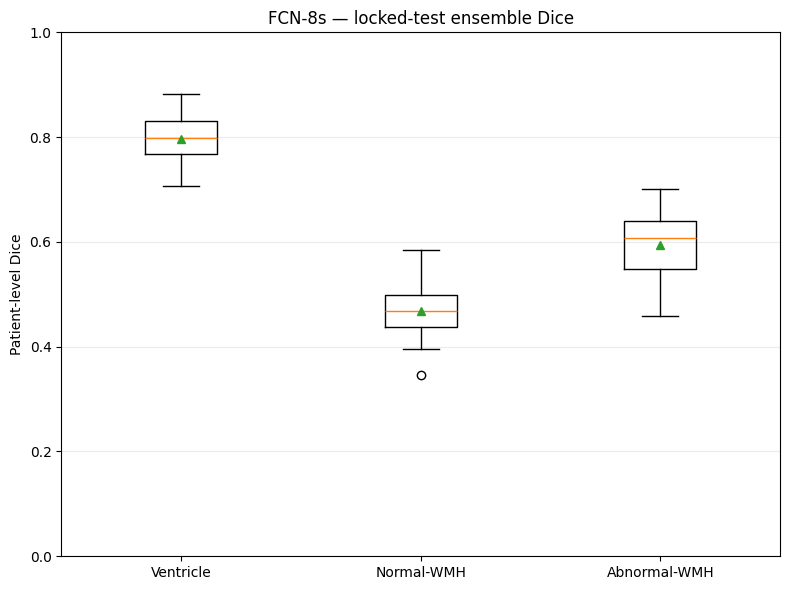

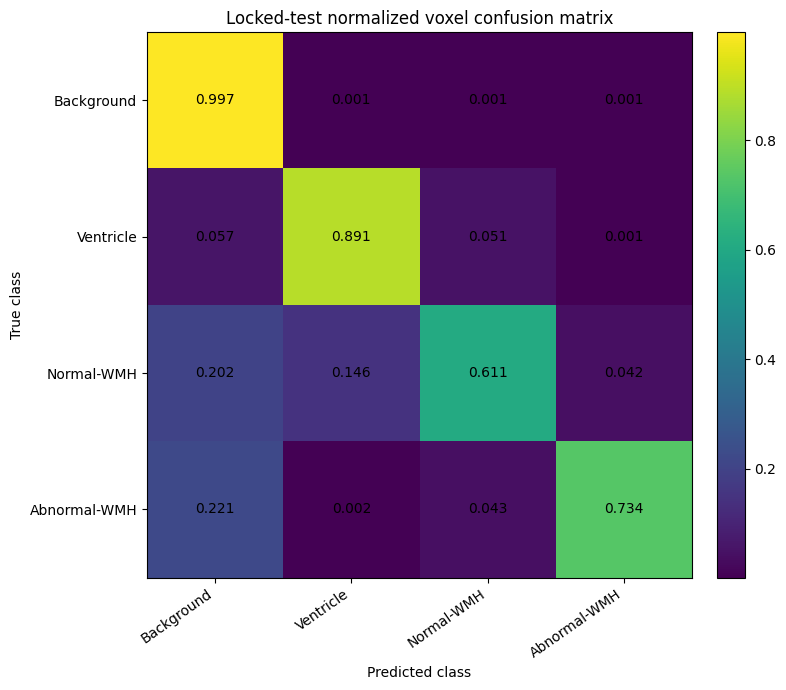

In [15]:
# Locked-test figures.
dice_columns = [
    "ventricle_dice",
    "normal_wmh_dice",
    "abnormal_wmh_dice",
]
dice_labels = [
    "Ventricle",
    "Normal-WMH",
    "Abnormal-WMH",
]

plt.figure(figsize=(8, 6))
plt.boxplot(
    [
        patient_metrics_df[c]
        .dropna()
        .to_numpy()
        for c in dice_columns
    ],
    tick_labels=dice_labels,
    showmeans=True,
)
plt.ylabel("Patient-level Dice")
plt.title(
    "FCN-8s — locked-test ensemble Dice"
)
plt.ylim(0, 1)
plt.grid(
    axis="y",
    alpha=0.25,
)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "fcn8s_locked_test_dice_boxplot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "fcn8s_locked_test_dice_boxplot.pdf",
    bbox_inches="tight",
)
plt.show()


cm = global_confusion.astype(float)
normalized_cm = cm / np.maximum(
    cm.sum(axis=1, keepdims=True),
    1,
)

plt.figure(figsize=(8, 7))
image = plt.imshow(
    normalized_cm,
    interpolation="nearest",
)
plt.colorbar(
    image,
    fraction=0.046,
    pad=0.04,
)

axis_labels = [
    "Background",
    "Ventricle",
    "Normal-WMH",
    "Abnormal-WMH",
]

plt.xticks(
    range(4),
    axis_labels,
    rotation=35,
    ha="right",
)
plt.yticks(
    range(4),
    axis_labels,
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(
    "Locked-test normalized voxel confusion matrix"
)

for r in range(4):
    for c in range(4):
        plt.text(
            c,
            r,
            f"{normalized_cm[r, c]:.3f}",
            ha="center",
            va="center",
        )

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "fcn8s_locked_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    FIGURE_DIR / "fcn8s_locked_test_confusion_matrix.pdf",
    bbox_inches="tight",
)
plt.show()


In [16]:
# Freeze and document the final test protocol.
final_metadata = {
    "model": "Reimplemented FCN-8s baseline under common protocol",
    "stage": "final_locked_test",
    "locked_test_patients": 20,
    "ensemble_members": 5,
    "ensemble_rule": "equal-weight mean softmax probability",
    "decision_rule": "argmax of ensemble mean probability",
    "checkpoint_rule": (
        "best_model.pt from each fold, selected during training "
        "by the pre-existing balanced validation score"
    ),
    "threshold_tuning_on_test": False,
    "calibration_fitted_on_test": False,
    "postprocessing_optimized_on_test": False,
    "retraining_performed": False,
    "split_sha256": EXPECTED_SPLIT_SHA256,
    "bootstrap_ci_replicates": BOOTSTRAP_REPLICATES,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "scientific_note": (
        "This is the final locked-test result under the frozen baseline "
        "inference rule. Do not change model, ensemble weights, thresholds, "
        "or post-processing after observing the test result."
    ),
}

(OUTPUT_DIR / "final_locked_test_metadata.json").write_text(
    json.dumps(final_metadata, indent=2),
    encoding="utf-8",
)

archive_path = shutil.make_archive(
    "/kaggle/working/MS3SEG_FCN8S_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("\nFINAL LOCKED-TEST EVALUATION COMPLETE")
print("Model: FCN-8s")
print("Download:")
print("/kaggle/working/MS3SEG_FCN8S_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS.zip")
print()
print(
    "Protocol is frozen. Do not tune this baseline or its inference rule "
    "using the test results."
)



FINAL LOCKED-TEST EVALUATION COMPLETE
Model: FCN-8s
Download:
/kaggle/working/MS3SEG_FCN8S_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS.zip

Protocol is frozen. Do not tune this baseline or its inference rule using the test results.


## After this run

Download:

`MS3SEG_FCN8S_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS.zip`

Then upload the result ZIP back to this chat.

Do **not** change the FCN-8s model, thresholds, ensemble weights, or post-processing after seeing the locked-test result.
